# 01 - Data audit
Goal: understand the raw CSV before modelling. We only **read** the raw file, we never change it.


In [1]:
# AI-GENERATED (Claude via Antigravity)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)   # where plots are saved
df = pd.read_csv("../data/raw/dengue_srilanka_full_2006_2025.csv")          # read-only load

## 1. Basic look: shape, columns, types, missing values, duplicates


In [2]:
# AI-GENERATED (Claude via Antigravity)
print("Shape (rows, columns):", df.shape)
print("Duplicate rows:", df.duplicated().sum())
audit = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "missing_%": (df.isna().mean()*100).round(2)})
display(audit)
display(df.describe().T)

Shape (rows, columns): (24775, 28)
Duplicate rows: 0


,dtype,missing,missing_%
year,int64,0,0.0
week,int64,0,0.0
start.date,str,0,0.0
end.date,str,0,0.0
month,int64,0,0.0
season,str,0,0.0
monsoon_season,str,0,0.0
is_epidemic_year,int64,0,0.0
district,str,0,0.0
province,str,0,0.0


,count,mean,std,min,25%,50%,75%,max
year,24775.0,2015.980827,5.480526,2006.000000,2011.000000,2016.000000,2.021000e+03,2.025000e+03
week,24775.0,26.580222,15.056451,1.000000,14.000000,27.000000,4.000000e+01,5.300000e+01
month,24775.0,6.526741,3.447094,1.000000,4.000000,7.000000,1.000000e+01,1.200000e+01
is_epidemic_year,24775.0,0.158426,0.365147,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00
latitude,24775.0,7.586808,1.035870,5.948500,6.927100,7.297500,8.311400e+00,9.661500e+00
longitude,24775.0,80.589556,0.535197,79.828300,80.221000,80.497100,8.101880e+01,8.170000e+01
coastal_district,24775.0,0.560000,0.496397,0.000000,0.000000,1.000000,1.000000e+00,1.000000e+00
area_km2,24775.0,2624.400000,1493.732526,699.000000,1652.000000,1996.000000,3.072000e+03,7.179000e+03
population,24775.0,849851.851948,602238.635259,89200.000000,460109.000000,750727.000000,1.104000e+06,2.498473e+06
population_density,24775.0,496.316298,694.278122,35.241498,130.519571,267.291683,6.107317e+02,3.574353e+03


## 2. Which columns are which?
From the header of the file:
- **District column:** `district` (`province` is the bigger region)
- **Date columns:** `year`, `week`, `start.date`, `end.date` (plus `month`)
- **Case count column:** `cases`

**My proposed target: `cases`** (raw weekly dengue cases per district). Please confirm.
Note: `incidence_rate` is a size-fair version of cases, but it is computed *from* cases, so it is a leakage risk (see section 6).


In [3]:
# AI-GENERATED (Claude via Antigravity)
TARGET, DISTRICT = "cases", "district"
df["start.date"] = pd.to_datetime(df["start.date"]); df["end.date"] = pd.to_datetime(df["end.date"])
print("Districts:", df[DISTRICT].nunique(), "| Date range:", df["start.date"].min().date(), "to", df["start.date"].max().date())

Districts: 25 | Date range: 2006-12-23 to 2025-12-13


## 3. Is every district a continuous weekly series?


In [4]:
# AI-GENERATED (Claude via Antigravity)
rows = []
for d, g in df.sort_values("start.date").groupby(DISTRICT):
    step = g["start.date"].diff().dt.days.dropna()          # days between neighbouring rows
    rows.append({"district": d, "weeks": len(g), "first": g["start.date"].min().date(), "last": g["start.date"].max().date(),
                 "gaps (step != 7 days)": int((step != 7).sum()), "duplicate weeks": int(g["start.date"].duplicated().sum())})
gaps = pd.DataFrame(rows); display(gaps)
print("Total gaps:", gaps["gaps (step != 7 days)"].sum())

,district,weeks,first,last,gaps (step != 7 days),duplicate weeks
0,Ampara,991,2006-12-23,2025-12-13,2,0
1,Anuradhapura,991,2006-12-23,2025-12-13,2,0
2,Badulla,991,2006-12-23,2025-12-13,2,0
3,Batticaloa,991,2006-12-23,2025-12-13,2,0
4,Colombo,991,2006-12-23,2025-12-13,2,0
5,Galle,991,2006-12-23,2025-12-13,2,0
6,Gampaha,991,2006-12-23,2025-12-13,2,0
7,Hambantota,991,2006-12-23,2025-12-13,2,0
8,Jaffna,991,2006-12-23,2025-12-13,2,0
9,Kalutara,991,2006-12-23,2025-12-13,2,0


Total gaps: 50


## 4. Plots: time, seasonality, distribution, district sizes


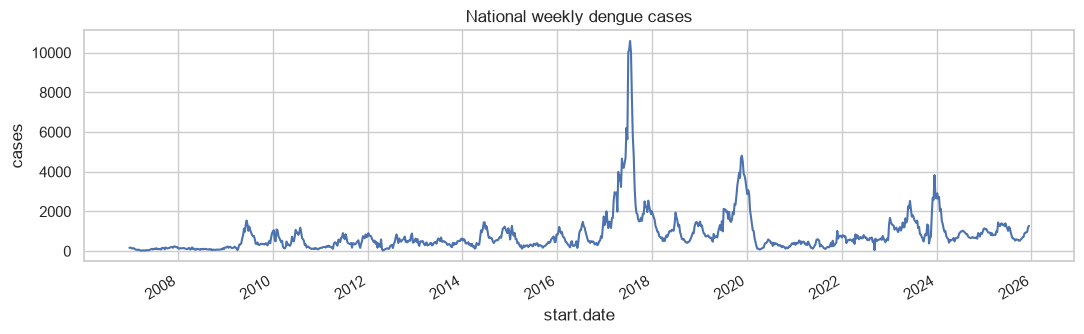

In [5]:
# AI-GENERATED (Claude via Antigravity)
# 4a. National total cases per week
nat = df.groupby("start.date")[TARGET].sum()
ax = nat.plot(figsize=(11,3.5), title="National weekly dengue cases"); ax.set_ylabel("cases")
plt.tight_layout(); plt.savefig(FIG/"01_national_total.png", dpi=120); plt.show()

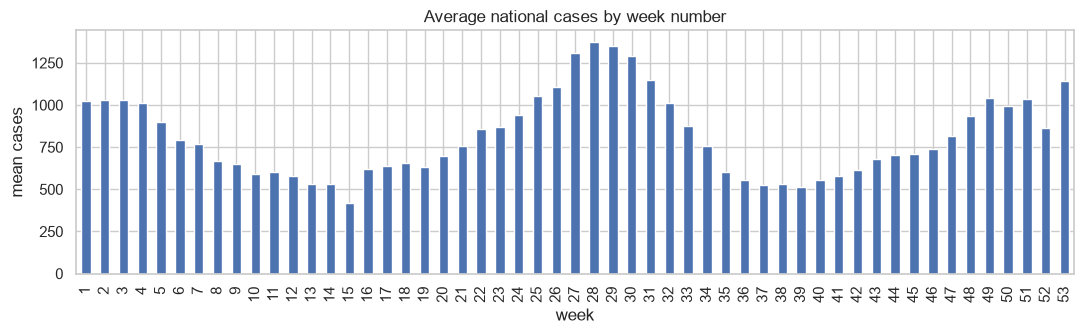

In [6]:
# AI-GENERATED (Claude via Antigravity)
# 4b. Seasonality: average national cases by week number
season = df.groupby(["year","week"])[TARGET].sum().groupby("week").mean()
ax = season.plot(kind="bar", figsize=(11,3.5), title="Average national cases by week number"); ax.set_ylabel("mean cases")
plt.tight_layout(); plt.savefig(FIG/"02_seasonality.png", dpi=120); plt.show()

Share of zero weeks: 13.0%
Skewness: 10.23 | mean: 32.4 | median: 10.0 | max: 2631


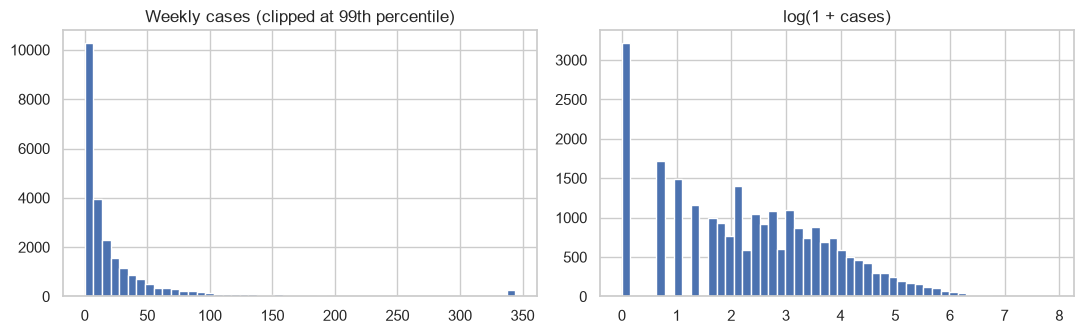

In [7]:
# AI-GENERATED (Claude via Antigravity)
# 4c. Distribution of weekly district cases: zeros and skew
print("Share of zero weeks: %.1f%%" % ((df[TARGET]==0).mean()*100))
print("Skewness:", round(df[TARGET].skew(),2), "| mean:", round(df[TARGET].mean(),1), "| median:", df[TARGET].median(), "| max:", df[TARGET].max())
fig, ax = plt.subplots(1, 2, figsize=(11,3.5))
df[TARGET].clip(upper=df[TARGET].quantile(0.99)).hist(bins=50, ax=ax[0]); ax[0].set_title("Weekly cases (clipped at 99th percentile)")
np.log1p(df[TARGET]).hist(bins=50, ax=ax[1]); ax[1].set_title("log(1 + cases)")
plt.tight_layout(); plt.savefig(FIG/"03_distribution.png", dpi=120); plt.show()

{'Mullaitivu': 96310, 'Monaragala': 481215, 'Nuwara Eliya': 749240, 'Galle': 1105318, 'Colombo': 2394214}


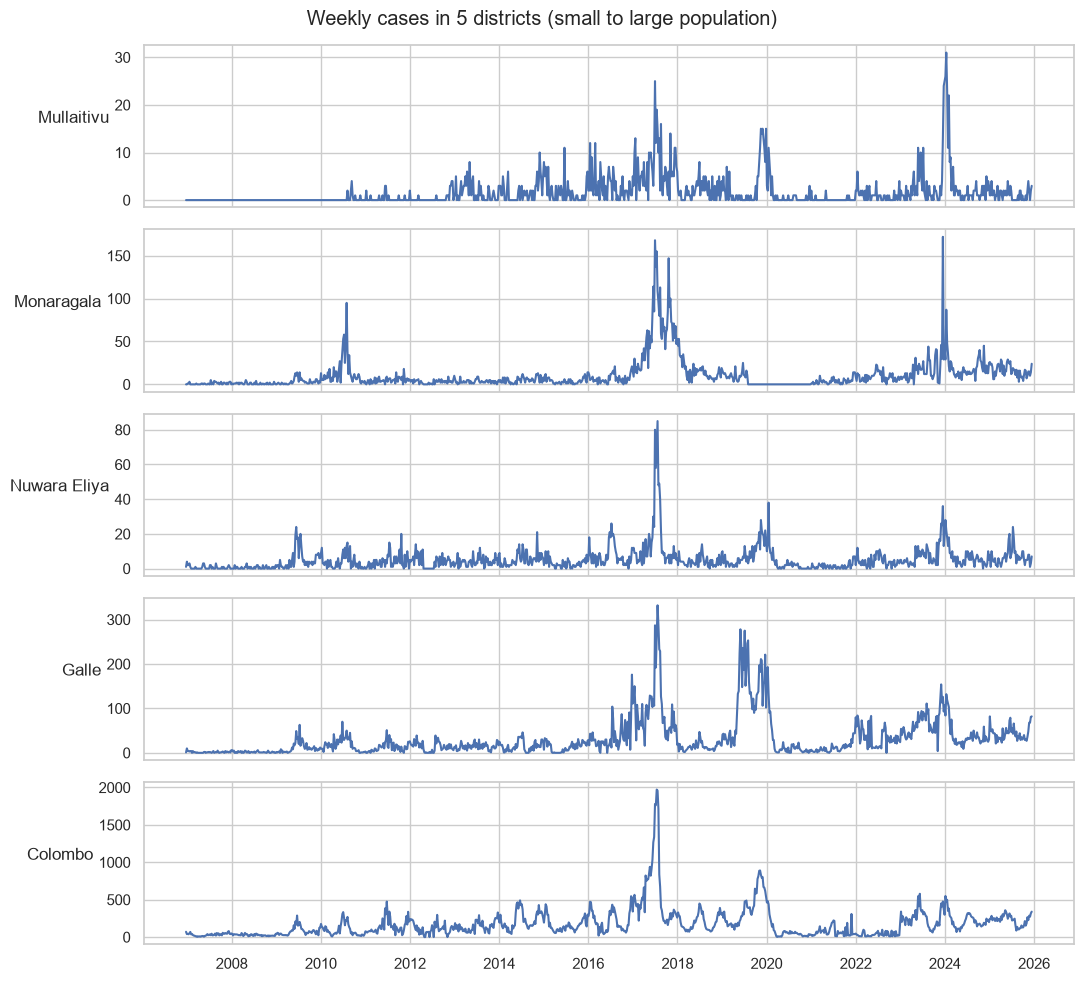

In [8]:
# AI-GENERATED (Claude via Antigravity)
# 4d. Five districts of different sizes (average population: smallest ... largest)
pop = df.groupby(DISTRICT)["population"].mean().sort_values()
five = [pop.index[int(i)] for i in np.linspace(0, len(pop)-1, 5)]
print({d: int(pop[d]) for d in five})
fig, axes = plt.subplots(5, 1, figsize=(11,10), sharex=True)
for a, d in zip(axes, five):
    s = df[df[DISTRICT]==d].set_index("start.date")[TARGET]; a.plot(s); a.set_ylabel(d, rotation=0, ha="right")
plt.suptitle("Weekly cases in 5 districts (small to large population)"); plt.tight_layout()
plt.savefig(FIG/"04_five_districts.png", dpi=120); plt.show()

## 5. Correlation of the target with each climate column


,pearson,spearman
rainfall_mm,0.067,0.183
rainfall_lag2,0.085,0.217
rainfall_lag4,0.108,0.245
temp_max_c,-0.030,-0.124
temp_min_c,0.023,-0.161
humidity_pct,0.116,0.228


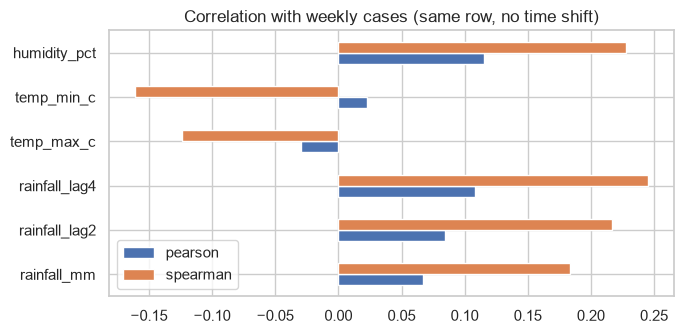

In [9]:
# AI-GENERATED (Claude via Antigravity)
climate = ["rainfall_mm","rainfall_lag2","rainfall_lag4","temp_max_c","temp_min_c","humidity_pct"]
corr = pd.DataFrame({"pearson": df[climate+[TARGET]].corr()[TARGET], "spearman": df[climate+[TARGET]].corr(method="spearman")[TARGET]}).drop(TARGET)
display(corr.round(3))
corr.plot(kind="barh", figsize=(7,3.5), title="Correlation with weekly cases (same row, no time shift)")
plt.tight_layout(); plt.savefig(FIG/"05_climate_correlation.png", dpi=120); plt.show()

## 6. Column dictionary and leakage risk
Meanings are my **interpretation of the names** (marked "?" when unsure). Leakage = the column is computed from the current week's cases, so it would not be known when forecasting.
The first cell below tests my guesses about `cases_lag1`, `incidence_rate` and `cases_zscore`.


In [10]:
# AI-GENERATED (Claude via Antigravity)
df = df.sort_values([DISTRICT, "start.date"])
print("Share of rows where cases_lag1 equals last week's cases:", (df.groupby(DISTRICT)[TARGET].shift(1).fillna(-1) == df["cases_lag1"].fillna(-1)).mean().round(4))
ratio = (df["incidence_rate"] * df["population"] / 1e5) / df[TARGET].replace(0, np.nan)
print("incidence_rate*population/100000 / cases (median; ~1 means derived from cases):", ratio.median().round(3))
print("Correlation cases vs incidence_rate:", df[[TARGET,"incidence_rate"]].corr().iloc[0,1].round(3), "| cases vs cases_zscore:", df[[TARGET,"cases_zscore"]].corr().iloc[0,1].round(3))
print("Epidemic-year flag by year:", df.groupby("year")["is_epidemic_year"].max().to_dict())

Share of rows where cases_lag1 equals last week's cases: 1.0
incidence_rate*population/100000 / cases (median; ~1 means derived from cases): 1.0
Correlation cases vs incidence_rate: 0.755 | cases vs cases_zscore: 0.63
Epidemic-year flag by year: {2006: 0, 2007: 0, 2008: 0, 2009: 1, 2010: 0, 2011: 0, 2012: 0, 2013: 0, 2014: 0, 2015: 0, 2016: 0, 2017: 1, 2018: 0, 2019: 1, 2020: 0, 2021: 0, 2022: 0, 2023: 0, 2024: 0, 2025: 0}


In [11]:
# AI-GENERATED (Claude via Antigravity)
info = {  # column: (meaning, leakage risk, reason)
 "year": ("calendar year of the week", "low", "known in advance"),
 "week": ("week number within the year", "low", "known in advance"),
 "start.date": ("first day of the week", "low", "known in advance; use for time ordering"),
 "end.date": ("last day of the week", "low", "known in advance"),
 "month": ("calendar month", "low", "known in advance"),
 "season": ("Sri Lankan farming season (Maha/Yala)", "low", "calendar-based"),
 "monsoon_season": ("monsoon period label", "low", "calendar-based"),
 "is_epidemic_year": ("flag: year counted as an epidemic year?", "high", "probably derived from yearly case totals, including future weeks of that year (check output above)"),
 "district": ("district name", "low", "fixed label"),
 "province": ("province of district", "low", "fixed label"),
 "latitude": ("district latitude", "low", "fixed"),
 "longitude": ("district longitude", "low", "fixed"),
 "coastal_district": ("1 if coastal", "low", "fixed"),
 "elevation_category": ("Low/Mid/High elevation", "low", "fixed"),
 "area_km2": ("district area", "low", "fixed"),
 "population": ("district population", "low", "external statistic, not from cases (some values are 'predicted')"),
 "population_source": ("whether population is actual or predicted", "low", "metadata only"),
 "population_density": ("population / area", "low", "derived from population and area"),
 "cases": ("weekly dengue cases (TARGET)", "target", "this is what we predict"),
 "incidence_rate": ("cases per 100,000 people (rate)?", "high", "computed from this week's cases"),
 "cases_lag1": ("cases of the previous week", "low", "past data only; fine for 1-week-ahead forecasts"),
 "cases_zscore": ("standardised cases (z-score)?", "high", "computed from this week's cases; mean/std may also use future weeks"),
 "rainfall_mm": ("weekly rainfall", "low", "weather, not from cases (same-week, so a forecast is needed in real use)"),
 "rainfall_lag2": ("rainfall 2 weeks earlier", "low", "past weather"),
 "rainfall_lag4": ("rainfall 4 weeks earlier", "low", "past weather"),
 "temp_max_c": ("max temperature", "low", "weather (same-week)"),
 "temp_min_c": ("min temperature", "low", "weather (same-week)"),
 "humidity_pct": ("humidity", "low", "weather (same-week)"),
}
print("Columns not described:", set(df.columns) - set(info), "| described but absent:", set(info) - set(df.columns))
table = pd.DataFrame([{"name": c, "type": str(df[c].dtype), "meaning": info[c][0], "leakage risk": info[c][1], "reason": info[c][2]} for c in df.columns])
pd.set_option("display.max_colwidth", 100); display(table)

Columns not described: set() | described but absent: set()


,name,type,meaning,leakage risk,reason
0,year,int64,calendar year of the week,low,known in advance
1,week,int64,week number within the year,low,known in advance
2,start.date,datetime64[us],first day of the week,low,known in advance; use for time ordering
3,end.date,datetime64[us],last day of the week,low,known in advance
4,month,int64,calendar month,low,known in advance
5,season,str,Sri Lankan farming season (Maha/Yala),low,calendar-based
6,monsoon_season,str,monsoon period label,low,calendar-based
7,is_epidemic_year,int64,flag: year counted as an epidemic year?,high,"probably derived from yearly case totals, including future weeks of that year (check output above)"
8,district,str,district name,low,fixed label
9,province,str,province of district,low,fixed label
